# Tarificación de RC de automóviles: GLM frente a gradient boosting

Prima pura (frecuencia × severidad) de la cartera freMTPL: 413.169 pólizas de RC de automóviles con su exposición y número de siniestros, y 16.181 importes. Comparo un GLM de Poisson con un gradient boosting para la frecuencia y uso un GLM Gamma para la severidad.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
SEED = 2026
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR = {"GLM": "#3E6470", "GBM": "#D9822B", "Observado": "#25292E"}

## 1. Datos y análisis exploratorio con SQL

In [2]:
freq = pd.read_csv(ROOT / "data" / "freMTPLfreq.csv.gz", index_col=0)
sev = pd.read_csv(ROOT / "data" / "freMTPLsev.csv.gz", index_col=0)
freq["Exposure"] = freq["Exposure"].clip(upper=1.0)   # exposición máxima de un año
print(freq.shape, sev.shape)
freq.head()

(413169, 10) (16181, 2)


,PolicyID,ClaimNb,Exposure,Power,CarAge,DriverAge,Brand,Gas,Region,Density
1,1,0,0.0900,g,0,46,Japanese (except Nissan) or Korean,Diesel,Aquitaine,76
2,2,0,0.8400,g,0,46,Japanese (except Nissan) or Korean,Diesel,Aquitaine,76
3,3,0,0.5200,f,2,38,Japanese (except Nissan) or Korean,Regular,Nord-Pas-de-Calais,3003
4,4,0,0.4500,f,2,38,Japanese (except Nissan) or Korean,Regular,Nord-Pas-de-Calais,3003
5,5,0,0.1500,g,0,41,Japanese (except Nissan) or Korean,Diesel,Pays-de-la-Loire,60


In [3]:
con = sqlite3.connect(":memory:")
freq.to_sql("polizas", con, index=False)
sev.to_sql("siniestros", con, index=False)

sql = lambda q: pd.read_sql(q, con)
sql('''
SELECT COUNT(*)                         AS polizas,
       ROUND(SUM(Exposure), 0)          AS exposicion_anios,
       SUM(ClaimNb)                     AS siniestros,
       ROUND(SUM(ClaimNb) / SUM(Exposure), 4) AS frecuencia_anual
FROM polizas
''')

,polizas,exposicion_anios,siniestros,frecuencia_anual
0,413169,"231,780.0000",16181,0.0698


In [4]:
# Frecuencia por tramo de edad del conductor
sql('''
SELECT CASE WHEN DriverAge < 21 THEN '18-20'
            WHEN DriverAge < 25 THEN '21-24'
            WHEN DriverAge < 30 THEN '25-29'
            WHEN DriverAge < 40 THEN '30-39'
            WHEN DriverAge < 50 THEN '40-49'
            WHEN DriverAge < 60 THEN '50-59'
            WHEN DriverAge < 70 THEN '60-69'
            ELSE '70+' END            AS tramo_edad,
       ROUND(SUM(Exposure), 0)        AS exposicion,
       SUM(ClaimNb)                   AS siniestros,
       ROUND(SUM(ClaimNb) / SUM(Exposure), 4) AS frecuencia
FROM polizas
GROUP BY tramo_edad
ORDER BY tramo_edad
''')

,tramo_edad,exposicion,siniestros,frecuencia
0,18-20,"1,811.0000",435,0.2402
1,21-24,"6,851.0000",908,0.1325
2,25-29,"16,958.0000",1440,0.0849
3,30-39,"52,943.0000",3458,0.0653
4,40-49,"56,522.0000",4001,0.0708
5,50-59,"51,385.0000",3358,0.0654
6,60-69,"24,727.0000",1414,0.0572
7,70+,"20,585.0000",1167,0.0567


In [5]:
# Coste medio y frecuencia por combustible y región (JOIN entre pólizas y siniestros)
sql('''
WITH coste AS (
    SELECT PolicyID, SUM(ClaimAmount) AS importe
    FROM siniestros GROUP BY PolicyID
)
SELECT p.Region,
       ROUND(SUM(p.ClaimNb) / SUM(p.Exposure), 4)        AS frecuencia,
       ROUND(SUM(c.importe) / SUM(p.ClaimNb), 0)          AS coste_medio,
       ROUND(SUM(COALESCE(c.importe, 0)) / SUM(p.Exposure), 1) AS prima_pura_observada
FROM polizas p LEFT JOIN coste c ON p.PolicyID = c.PolicyID
GROUP BY p.Region
ORDER BY prima_pura_observada DESC
''')

,Region,frecuencia,coste_medio,prima_pura_observada
0,Centre,0.0630,"2,630.0000",165.8000
1,Ile-de-France,0.0858,"1,760.0000",151.1000
2,Nord-Pas-de-Calais,0.0822,"1,734.0000",142.5000
3,Bretagne,0.0674,"2,085.0000",140.6000
4,Basse-Normandie,0.0679,"2,056.0000",139.7000
5,Aquitaine,0.0737,"1,816.0000",133.9000
6,Pays-de-la-Loire,0.0719,"1,632.0000",117.3000
7,Limousin,0.0822,"1,423.0000",117.1000
8,Poitou-Charentes,0.0717,"1,632.0000",117.0000
9,Haute-Normandie,0.0693,"1,488.0000",103.1000


## 2. Preparación de variables

- Edad del conductor y antigüedad del vehículo en tramos para el GLM (relaciones no lineales) y en continuo para el GBM.
- Densidad de población en logaritmo.
- En cada variable categórica, el nivel de referencia del GLM es el de mayor exposición (práctica habitual en tarificación).

In [6]:
def prepare(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["DriverBand"] = pd.cut(out["DriverAge"], [17, 20, 24, 29, 39, 49, 59, 69, 120],
                               labels=["18-20", "21-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70+"])
    out["CarBand"] = pd.cut(out["CarAge"], [-1, 0, 2, 5, 9, 14, 200],
                            labels=["0", "1-2", "3-5", "6-9", "10-14", "15+"])
    out["LogDensity"] = np.log(out["Density"])
    return out

data = prepare(freq)
CATS = ["DriverBand", "CarBand", "Power", "Brand", "Gas", "Region"]
for c in CATS:   # nivel de referencia = el de mayor exposición
    order = data.groupby(c, observed=True)["Exposure"].sum().sort_values(ascending=False).index
    data[c] = pd.Categorical(data[c].astype(str), categories=[str(x) for x in order])

train, test = train_test_split(data, test_size=0.2, random_state=SEED)
print(f"Entrenamiento: {len(train):,} pólizas · Test: {len(test):,} pólizas")

Entrenamiento: 330,535 pólizas · Test: 82,634 pólizas


## 3. Frecuencia: GLM de Poisson

In [7]:
formula = "ClaimNb ~ DriverBand + CarBand + Power + Brand + Gas + Region + LogDensity"
glm_freq = smf.glm(formula, data=train, family=sm.families.Poisson(),
                   offset=np.log(train["Exposure"])).fit()
print(f"Devianza: {glm_freq.deviance:,.0f} · AIC: {glm_freq.aic:,.0f} · parámetros: {len(glm_freq.params)}")

rel = (np.exp(glm_freq.params).rename("Relatividad").to_frame()
       .join(glm_freq.pvalues.rename("p-valor")))
rel.loc[rel.index.str.startswith("DriverBand")]

Devianza: 83,463 · AIC: 108,732 · parámetros: 41


,Relatividad,p-valor
DriverBand[T.30-39],0.9052,0.0001
DriverBand[T.50-59],0.9348,0.0096
DriverBand[T.60-69],0.8348,0.0000
DriverBand[T.70+],0.8822,0.0009
DriverBand[T.25-29],1.1458,0.0001
DriverBand[T.21-24],1.8598,0.0000
DriverBand[T.18-20],3.5596,0.0000


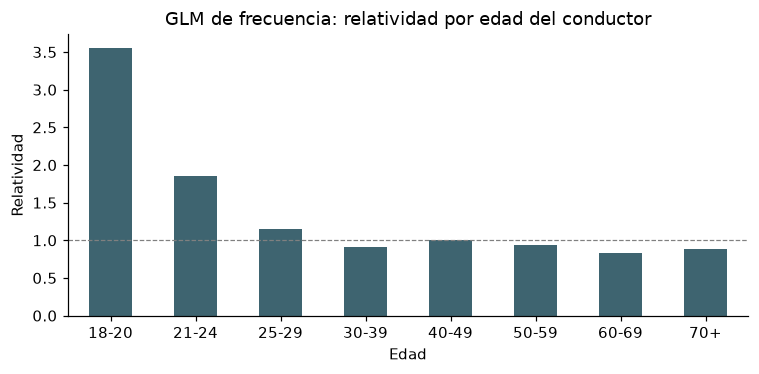

In [8]:
# Relatividades por edad del conductor (referencia = tramo con más exposición)
levels = data["DriverBand"].cat.categories
r = pd.Series({lv: np.exp(glm_freq.params.get(f"DriverBand[T.{lv}]", 0.0)) for lv in levels})
r = r[["18-20", "21-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70+"]]
ax = r.plot.bar(color=COLOR["GLM"], figsize=(7, 3.5), rot=0)
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.set(title="GLM de frecuencia: relatividad por edad del conductor", xlabel="Edad", ylabel="Relatividad")
plt.tight_layout(); plt.savefig(FIG / "relatividades_edad.png"); plt.show()

## 4. Frecuencia: gradient boosting con pérdida de Poisson

`HistGradientBoostingRegressor` de scikit-learn con `loss="poisson"`. El objetivo es la frecuencia anual
(`ClaimNb / Exposure`) ponderada por la exposición, que es equivalente al GLM con *offset*.

In [9]:
FEATURES = ["DriverAge", "CarAge", "LogDensity", "Power", "Brand", "Gas", "Region"]
CAT_GBM = ["Power", "Brand", "Gas", "Region"]

def gbm_matrix(df):
    X = df[FEATURES].copy()
    for c in CAT_GBM:
        X[c] = X[c].cat.codes
    return X

gbm_freq = HistGradientBoostingRegressor(
    loss="poisson", learning_rate=0.05, max_iter=600, max_leaf_nodes=31,
    min_samples_leaf=500, l2_regularization=1.0, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=30,
    categorical_features=[FEATURES.index(c) for c in CAT_GBM], random_state=SEED,
)
gbm_freq.fit(gbm_matrix(train), train["ClaimNb"] / train["Exposure"], sample_weight=train["Exposure"])
print(f"Iteraciones con early stopping: {gbm_freq.n_iter_}")

Iteraciones con early stopping: 130


## 5. Comparación en la muestra de test

In [10]:
test = test.copy()
test["freq_glm"] = glm_freq.predict(test, offset=np.zeros(len(test)))     # frecuencia anual
test["freq_gbm"] = gbm_freq.predict(gbm_matrix(test))
y_obs = test["ClaimNb"] / test["Exposure"]
w = test["Exposure"]
base = np.full(len(test), train["ClaimNb"].sum() / train["Exposure"].sum())

def gini(y, pred, weight):
    # Gini de la curva de Lorenz ordenada (pólizas ordenadas de menor a mayor riesgo predicho)
    order = np.argsort(pred)
    cum_w = np.cumsum(weight.to_numpy()[order]) / weight.sum()
    cum_y = np.cumsum((y * weight).to_numpy()[order]) / (y * weight).sum()
    return 1 - 2 * np.trapezoid(cum_y, cum_w), cum_w, cum_y

rows = {}
for name, pred in {"Frecuencia media": base, "GLM Poisson": test["freq_glm"], "GBM Poisson": test["freq_gbm"]}.items():
    rows[name] = {
        "Devianza de Poisson media": mean_poisson_deviance(y_obs, pred, sample_weight=w),
        "Gini": gini(y_obs, pd.Series(pred, index=test.index), w)[0],
        "Siniestros predichos / observados": (pred * w).sum() / test["ClaimNb"].sum(),
    }
metrics = pd.DataFrame(rows).T
metrics

,Devianza de Poisson media,Gini,Siniestros predichos / observados
Frecuencia media,0.4434,0.0060,1.0428
GLM Poisson,0.4351,0.1783,1.0425
GBM Poisson,0.4350,0.1790,1.0412


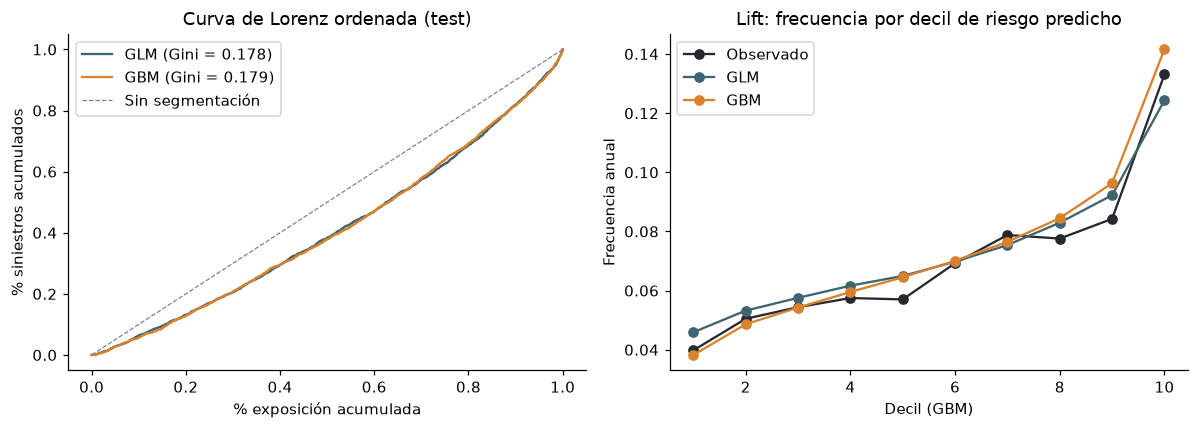

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, col in [("GLM", "freq_glm"), ("GBM", "freq_gbm")]:
    g, cw, cy = gini(y_obs, test[col], w)
    axes[0].plot(cw, cy, label=f"{name} (Gini = {g:.3f})", color=COLOR[name])
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8, label="Sin segmentación")
axes[0].set(title="Curva de Lorenz ordenada (test)", xlabel="% exposición acumulada", ylabel="% siniestros acumulados")
axes[0].legend()

test["decil"] = pd.qcut(test["freq_gbm"].rank(method="first"), 10, labels=range(1, 11))
g = (test.assign(n_glm=test["freq_glm"] * test["Exposure"], n_gbm=test["freq_gbm"] * test["Exposure"])
        .groupby("decil", observed=True)[["ClaimNb", "n_glm", "n_gbm", "Exposure"]].sum())
lift = pd.DataFrame({"Observado": g["ClaimNb"] / g["Exposure"],
                     "GLM": g["n_glm"] / g["Exposure"], "GBM": g["n_gbm"] / g["Exposure"]})
for c in lift.columns:
    axes[1].plot(lift.index.astype(int), lift[c], marker="o", label=c, color=COLOR[c])
axes[1].set(title="Lift: frecuencia por decil de riesgo predicho", xlabel="Decil (GBM)", ylabel="Frecuencia anual")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "lorenz_lift.png"); plt.show()

## 6. Severidad: GLM Gamma y grandes siniestros

Los grandes siniestros distorsionan el ajuste de la severidad. Se modelizan los siniestros hasta el percentil 99
con un GLM Gamma (enlace logarítmico) y el exceso sobre ese umbral se reparte como un recargo uniforme por siniestro.

In [12]:
claims = sev.merge(data.drop(columns="ClaimNb"), on="PolicyID", how="left")
threshold = claims["ClaimAmount"].quantile(0.99)
claims["Capped"] = claims["ClaimAmount"].clip(upper=threshold)
large_load = (claims["ClaimAmount"] - claims["Capped"]).sum() / len(claims)
print(f"Umbral de gran siniestro (P99): {threshold:,.0f} € · recargo por siniestro: {large_load:,.1f} €")
print(f"Peso de los grandes siniestros en el coste total: {(claims['ClaimAmount'] - claims['Capped']).sum() / claims['ClaimAmount'].sum():.1%}")

train_ids = set(train["PolicyID"])
claims_train = claims[claims["PolicyID"].isin(train_ids)]
glm_sev = smf.glm("Capped ~ DriverBand + CarBand + Power + Gas + LogDensity", data=claims_train,
                  family=sm.families.Gamma(sm.families.links.Log())).fit()
print(f"Coste medio limitado observado: {claims_train['Capped'].mean():,.0f} € · "
      f"dispersión Gamma: {glm_sev.scale:.2f}")

Umbral de gran siniestro (P99): 16,109 € · recargo por siniestro: 622.5 €
Peso de los grandes siniestros en el coste total: 29.2%
Coste medio limitado observado: 1,500 € · dispersión Gamma: 1.87


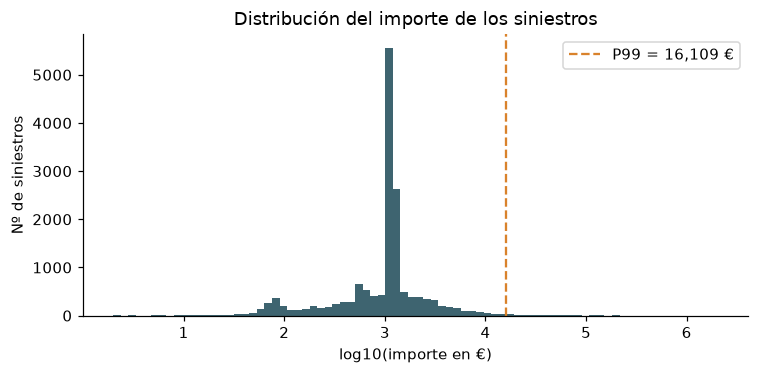

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(claims["ClaimAmount"]), bins=80, color=COLOR["GLM"])
ax.axvline(np.log10(threshold), color=COLOR["GBM"], ls="--", label=f"P99 = {threshold:,.0f} €")
ax.set(title="Distribución del importe de los siniestros", xlabel="log10(importe en €)", ylabel="Nº de siniestros")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "severidad.png"); plt.show()

## 7. Prima pura, calibración y ejemplos de tarifa

In [14]:
test["sev_glm"] = glm_sev.predict(test) + large_load
test["prima_glm"] = test["freq_glm"] * test["sev_glm"]
test["prima_gbm"] = test["freq_gbm"] * test["sev_glm"]

cost_test = claims[claims["PolicyID"].isin(set(test["PolicyID"]))]["ClaimAmount"].sum()
calib = pd.DataFrame({
    "Coste esperado (€)": [(test["prima_glm"] * w).sum(), (test["prima_gbm"] * w).sum()],
}, index=["GLM frecuencia × GLM severidad", "GBM frecuencia × GLM severidad"])
calib["Coste observado (€)"] = cost_test
calib["Ratio esperado / observado"] = calib["Coste esperado (€)"] / cost_test
calib.style.format("{:,.2f}")

,Coste esperado (€),Coste observado (€),Ratio esperado / observado
GLM frecuencia × GLM severidad,"6,925,998.81","6,541,712.00",1.06
GBM frecuencia × GLM severidad,"6,912,981.53","6,541,712.00",1.06


In [15]:
profiles = pd.DataFrame({
    "PolicyID": [0, 0, 0], "Exposure": [1, 1, 1],
    "DriverAge": [19, 45, 72], "CarAge": [1, 6, 12], "Density": [5000, 300, 60],
    "Power": ["i", "f", "d"], "Brand": ["Renault, Nissan or Citroen"] * 3,
    "Gas": ["Regular", "Diesel", "Regular"], "Region": ["Ile-de-France", "Centre", "Bretagne"],
}, index=["Joven urbano", "Adulto medio", "Mayor rural"])
p = prepare(profiles)
for c in CATS:
    p[c] = pd.Categorical(p[c].astype(str), categories=data[c].cat.categories)
tarifa = pd.DataFrame({
    "Frecuencia GLM": glm_freq.predict(p, offset=np.zeros(len(p))),
    "Frecuencia GBM": gbm_freq.predict(gbm_matrix(p)),
    "Coste medio (€)": glm_sev.predict(p) + large_load,
}, index=p.index)
tarifa["Prima pura GLM (€)"] = tarifa["Frecuencia GLM"] * tarifa["Coste medio (€)"]
tarifa["Prima pura GBM (€)"] = tarifa["Frecuencia GBM"] * tarifa["Coste medio (€)"]
tarifa.round(3)

,Frecuencia GLM,Frecuencia GBM,Coste medio (€),Prima pura GLM (€),Prima pura GBM (€)
Joven urbano,0.3800,0.3160,"2,730.9500","1,037.6870",863.6890
Adulto medio,0.0800,0.0760,"2,126.8140",169.2200,160.9540
Mayor rural,0.0420,0.0410,"2,077.2810",87.5150,84.8920
